In [23]:
# """India Street food body damager predictor"""

# 1. Import libraries
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score


In [25]:
# 2. Load the dataset

df = pd.read_csv("indian_street_food_dataset.csv")

print("First five rows:")
display(df.head())

print("Dataset shape:", df.shape)

First five rows:


,Momo,Pizza,Samosa,Pani_Puri,French_Fries,Soya_Bari,Burger,Patties,Chowmein,Dosa,Annual_Body_Damage_Percentage
0,6,0,0,15,5,14,0,2,1,5,26.03
1,19,9,6,9,5,14,6,4,13,4,60.80
2,14,2,11,9,12,13,10,13,3,1,54.08
3,10,3,5,16,11,4,5,1,0,6,36.71
4,7,3,12,11,19,9,9,8,15,8,63.62


Dataset shape: (50000, 11)


In [26]:
# 3. Explore the dataset
print("Column names:")
print(df.columns.tolist())

print("\nDataset information:")
df.info()

print("\nStatistical summary:")
display(df.describe())

print("\nMissing values:")
print(df.isnull().sum())

print("\nDuplicate rows:", df.duplicated().sum())

Column names:
['Momo', 'Pizza', 'Samosa', 'Pani_Puri', 'French_Fries', 'Soya_Bari', 'Burger', 'Patties', 'Chowmein', 'Dosa', 'Annual_Body_Damage_Percentage']

Dataset information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 50000 entries, 0 to 49999
Data columns (total 11 columns):
 #   Column                         Non-Null Count  Dtype  
---  ------                         --------------  -----  
 0   Momo                           50000 non-null  int64  
 1   Pizza                          50000 non-null  int64  
 2   Samosa                         50000 non-null  int64  
 3   Pani_Puri                      50000 non-null  int64  
 4   French_Fries                   50000 non-null  int64  
 5   Soya_Bari                      50000 non-null  int64  
 6   Burger                         50000 non-null  int64  
 7   Patties                        50000 non-null  int64  
 8   Chowmein                       50000 non-null  int64  
 9   Dosa                           50000 non-null 

,Momo,Pizza,Samosa,Pani_Puri,French_Fries,Soya_Bari,Burger,Patties,Chowmein,Dosa,Annual_Body_Damage_Percentage
count,50000.000000,50000.000000,50000.0000,50000.000000,50000.000000,50000.000000,50000.000000,50000.000000,50000.000000,50000.000000,50000.000000
mean,10.041280,5.007880,7.5340,9.982540,9.999100,7.497760,7.498600,7.461660,7.484740,7.493060,50.006568
std,6.045913,3.163621,4.6164,6.070658,6.043528,4.618158,4.622465,4.599699,4.607424,4.597453,10.051638
min,0.000000,0.000000,0.0000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,14.170000
25%,5.000000,2.000000,4.0000,5.000000,5.000000,3.000000,3.000000,3.000000,3.000000,4.000000,43.130000
50%,10.000000,5.000000,8.0000,10.000000,10.000000,7.000000,7.000000,7.000000,7.000000,7.000000,50.030000
75%,15.000000,8.000000,12.0000,15.000000,15.000000,12.000000,12.000000,11.000000,11.000000,11.250000,56.860000
max,20.000000,10.000000,15.0000,20.000000,20.000000,15.000000,15.000000,15.000000,15.000000,15.000000,87.430000



Missing values:
Momo                             0
Pizza                            0
Samosa                           0
Pani_Puri                        0
French_Fries                     0
Soya_Bari                        0
Burger                           0
Patties                          0
Chowmein                         0
Dosa                             0
Annual_Body_Damage_Percentage    0
dtype: int64

Duplicate rows: 0


In [27]:
# 4. Dataset cleaning
df = df.drop_duplicates()
df = df.dropna()

print("Shape after cleaning:", df.shape)
print("Missing values after cleaning:", df.isnull().sum().sum())

Shape after cleaning: (50000, 11)
Missing values after cleaning: 0


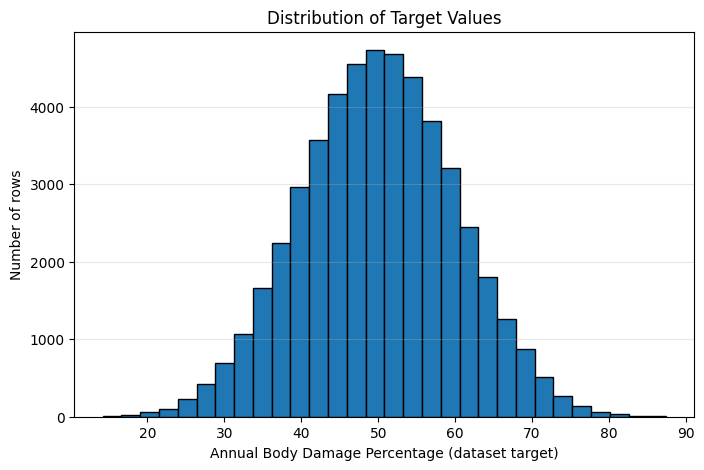

In [28]:
# 5. Visualize the target variable
plt.figure(figsize=(8, 5))
plt.hist(df["Annual_Body_Damage_Percentage"], bins=30, edgecolor="black")
plt.xlabel("Annual Body Damage Percentage (dataset target)")
plt.ylabel("Number of rows")
plt.title("Distribution of Target Values")
plt.grid(axis="y", alpha=0.3)
plt.show()

In [30]:
# 6. Define features (X) and target (y)
X = df.drop("Annual_Body_Damage_Percentage", axis=1)
y = df["Annual_Body_Damage_Percentage"]

print("Features shape:", X.shape)
print("Target shape:", y.shape)

display(X.head())
display(y.head())

Features shape: (50000, 10)
Target shape: (50000,)


,Momo,Pizza,Samosa,Pani_Puri,French_Fries,Soya_Bari,Burger,Patties,Chowmein,Dosa
0,6,0,0,15,5,14,0,2,1,5
1,19,9,6,9,5,14,6,4,13,4
2,14,2,11,9,12,13,10,13,3,1
3,10,3,5,16,11,4,5,1,0,6
4,7,3,12,11,19,9,9,8,15,8


,Annual_Body_Damage_Percentage
0,26.03
1,60.80
2,54.08
3,36.71
4,63.62


In [31]:
# 7. Split data into training and testing sets
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42
)

print("Training rows:", X_train.shape[0])
print("Testing rows:", X_test.shape[0])

Training rows: 40000
Testing rows: 10000


In [32]:
# 8. Create and train the Linear Regression model
model = LinearRegression()
model.fit(X_train, y_train)

print("Linear Regression model trained successfully!")

Linear Regression model trained successfully!


In [34]:
# 9. Predict on test data
y_pred = model.predict(X_test)

comparison = pd.DataFrame({
    "Actual Value": y_test.values,
    "Predicted Value": y_pred
})

display(comparison.head(10))

,Actual Value,Predicted Value
0,47.98,45.799847
1,39.73,38.118840
2,53.36,53.443632
3,41.02,38.792035
4,48.04,49.534053
5,61.10,57.027812
6,34.18,32.793167
7,41.53,40.592605
8,39.84,41.768872
9,57.10,57.968040


In [36]:
# Mean absolute error ------>>>
mae = mean_absolute_error(y_test, y_pred)
print("Mean Absolute Error:",mae)

# Mean Square Error ------->>>
mse = mean_squared_error(y_test, y_pred)
print("Mean Squared Error:",mse)

# Root Mean Squared Error -------->>
rmse = np.sqrt(mse)
print("Root Mean Squared Error:",rmse)

# R2 Score -------->>>>>
r2 = r2_score(y_test, y_pred)
print("R2 Score:", r2)

Mean Absolute Error: 1.600578395451405
Mean Squared Error: 4.004870946901099
Root Mean Squared Error: 2.0012173662301405
R2 Score: 0.9599179486398303


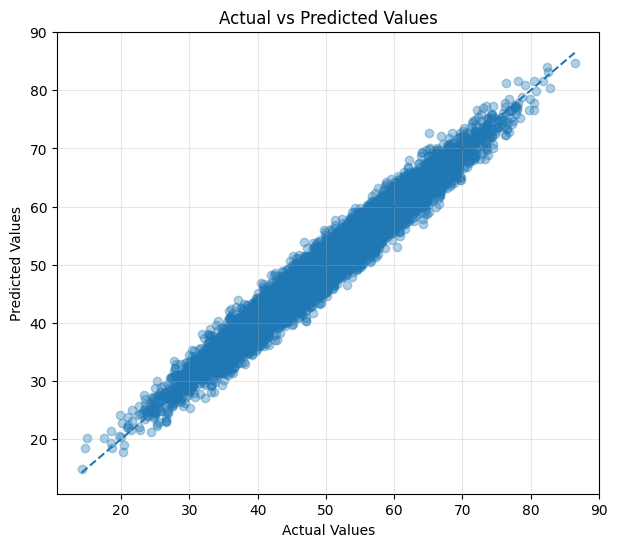

In [37]:
# 11. Graph: Actual values vs Predicted values
plt.figure(figsize=(7, 6))
plt.scatter(y_test, y_pred, alpha=0.35)

minimum = min(y_test.min(), y_pred.min())
maximum = max(y_test.max(), y_pred.max())
plt.plot([minimum, maximum], [minimum, maximum], linestyle="--")

plt.xlabel("Actual Values")
plt.ylabel("Predicted Values")
plt.title("Actual vs Predicted Values")
plt.grid(alpha=0.3)
plt.show()

In [38]:
# 12. Feature coefficients
coefficients = pd.DataFrame({
    "Feature": X.columns,
    "Coefficient": model.coef_
})

display(coefficients.sort_values("Coefficient", ascending=False))

,Feature,Coefficient
2,Samosa,0.755340
0,Momo,0.736005
1,Pizza,0.714878
8,Chowmein,0.694405
7,Patties,0.673702
6,Burger,0.603483
5,Soya_Bari,0.580544
9,Dosa,0.560050
4,French_Fries,0.539042
3,Pani_Puri,0.474854


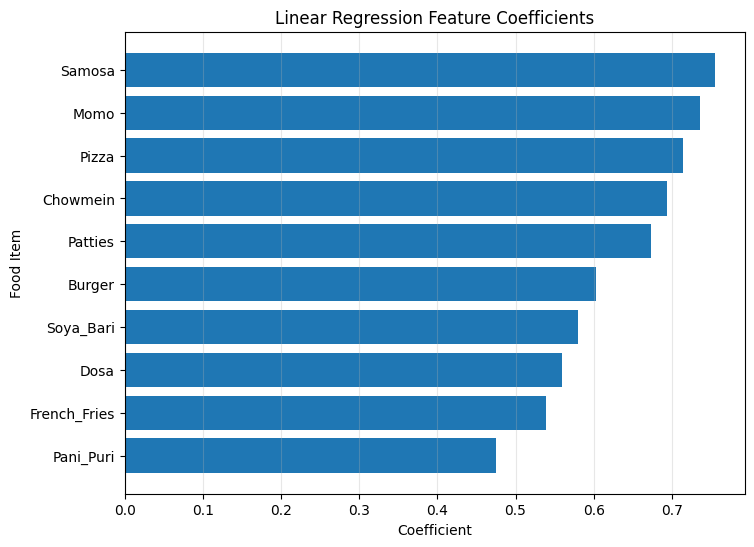

Intercept: -0.08518330904134075


In [39]:
# 13. Graph: Linear Regression coefficients
coefficients = coefficients.sort_values("Coefficient")

plt.figure(figsize=(8, 6))
plt.barh(coefficients["Feature"], coefficients["Coefficient"])
plt.xlabel("Coefficient")
plt.ylabel("Food Item")
plt.title("Linear Regression Feature Coefficients")
plt.grid(axis="x", alpha=0.3)
plt.show()

print("Intercept:", model.intercept_)

In [ ]:
# 14. Enter food consumption to get a prediction ------>>>

Momo = int(input("Momo (0-30): "))
Pizza = int(input("Pizza (0-30): "))
Samosa = int(input("Samosa (0-30): "))
Pani_Puri = int(input("Pani Puri (0-30): "))
French_Fries = int(input("French Fries (0-30): "))
Soya_Bari = int(input("Soya Bari (0-30): "))
Burger = int(input("Burger (0-30): "))
Patties = int(input("Patties (0-30): "))
Chowmein = int(input("Chowmein (0-30): "))
Dosa = int(input("Dosa (0-30): "))

user_data = pd.DataFrame({
    "Momo": [Momo],
    "Pizza": [Pizza],
    "Samosa": [Samosa],
    "Pani_Puri": [Pani_Puri],
    "French_Fries": [French_Fries],
    "Soya_Bari": [Soya_Bari],
    "Burger": [Burger],
    "Patties": [Patties],
    "Chowmein": [Chowmein],
    "Dosa": [Dosa]
})

prediction = model.predict(user_data)

print("Predicted target value:", round(prediction[0], 2), "%")